# Strip waveguide directional coupler - FDTD
This notebook contains code that simulates bend waveguide parameters using **Tidy3d**. \
The objective is to obtain loss values across radius sweep.

https://www.flexcompute.com/tidy3d/examples/notebooks/SbendCMAES

In [308]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install -r pyproject.toml

# Import modules
from datetime import datetime
import cma
from IPython.display import display
import lumapi as lma
import math
import matplotlib.pyplot as plt
import numpy as np
import photonix as px

In [309]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [310]:
# Constants

um = 1e-6
nm = 1e-9
C = 299792458

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [311]:
# Si3N4/SiO2 1000x360nm 1550nm
experiment_name = ""
wavelength_center = 1.55*um
wavelength_span = 0.15*um

# Slab
core_thickness = 360*nm
core_width = 1000*nm
bottom_clad_thickness = 5*um
top_clad_thickness = 5*um

# Coupler
coupler_gap = 400*nm
coupler_length = 12.15*um

# S-bend
s_bend_gds = "/workspace/GDS/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds"


# https://optics.ansys.com/hc/en-us/articles/360034394614-Material-Database-in-FDTD-and-MODE
base_core_material = "Si3N4 (Silicon Nitride) - Luke"
base_clad_material = "SiO2 (Glass) - Palik"
base_substrate_material = "Si (Silicon) - Palik"

In [312]:
# Pre-calculate parameters for solver
experiment_name = (
    f"{base_core_material.split()[0].lower()}_"
    f"w{int(core_width / nm)}nm_"
    f"h{int(core_thickness / nm)}nm_"
    f"directCoupler_"
    f"g{int(coupler_gap / nm)}nm_"
    f"l{int(coupler_length / um)}um"
)

substrate_thickness = 100*um

field_intensity_log_decay = -6

initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

frequency_center = C / wavelength_center

In [313]:
# Get solver
solver = lma.FDTD(hide=False)

In [314]:
# Helper for safe removal

def remove(object_name):
    try:
        solver.select(object_name)
        solver.delete()
    except:
        pass

def copy(original_name, copy_name):
    solver.select(original_name)
    solver.copy()
    solver.set("name", copy_name)

# Materials

In [315]:
# Materials fitting

def fit_material(material_name):
    wvl_min = wavelength_center - wavelength_span/2
    wvl_max = wavelength_center + wavelength_span/2

    try:
        solver.deletematerial(f"{material_name} Fitted")
    except:
        pass

    material_fitted = solver.copymaterial(material_name)
    
    material_params = {
        "tolerance": 0.001,
        "max coefficients": 6,
        "specify fit range": True,
        "wavelength min": wvl_min,
        "wavelength max": wvl_max,
        "name": f"{material_name} Fitted"
    }
    
    solver.setmaterial(material_fitted, material_params)
    
    return f"{material_name} Fitted"

core_material = fit_material(base_core_material)
clad_material = fit_material(base_clad_material)
substrate_material = fit_material(base_substrate_material)

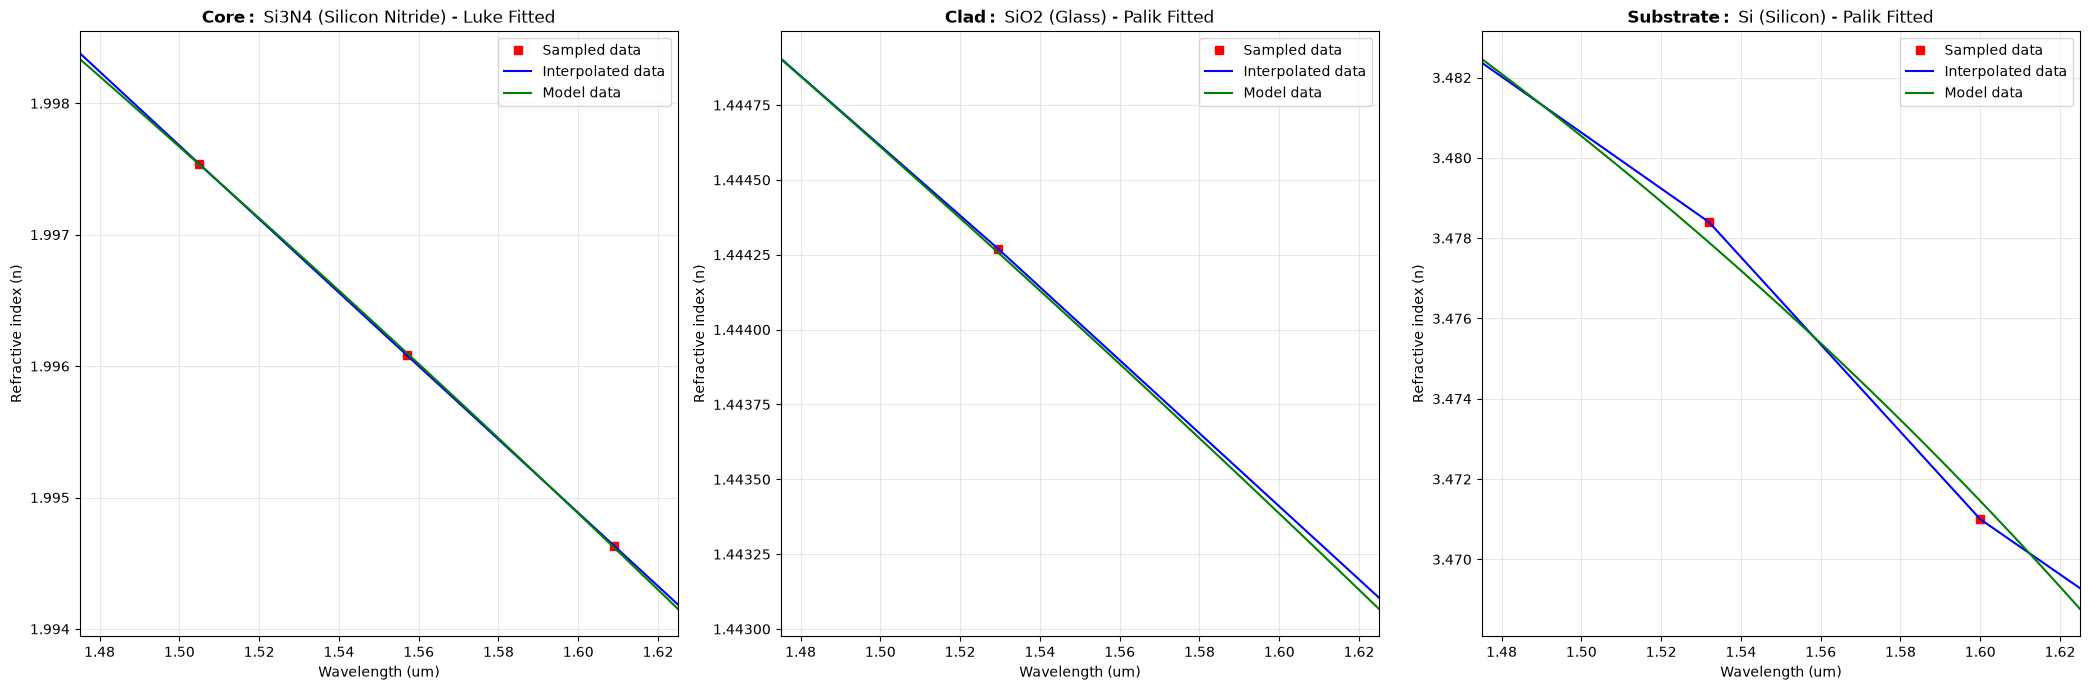

In [316]:
# Materials fit preview

def plot_material(material, ax):
    ax.set_title(material)

    wvl_min = solver.getmaterial(material, "wavelength min")
    wvl_max = solver.getmaterial(material, "wavelength max")

    mat_permitivity_samples = solver.getmaterial(material, "sampled data")

    f1 = mat_permitivity_samples[:, 0]
    mat_n_interpolated = solver.getindex(material, f1).squeeze()
    mat_n_interpolated = np.column_stack((f1, mat_n_interpolated))

    f2 = C / np.linspace(wvl_min, wvl_max, 100)
    fmin = np.min(f2)
    fmax = np.max(f2)
    mat_n_model = solver.getmodeindex(material, f2, 1, 1, 0, fmin, fmax);
    mat_n_model = np.column_stack((f2, mat_n_model))

    px.plot_material_n(
        mat_permitivity_samples,
        mat_n_interpolated,
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material}")

fig.tight_layout()
plt.show()

In [317]:
# Structure geometry

def import_gds(
    filename,
    cellname, 
    objname):
    solver.gdsimport(
        filename,
        cellname,
        1,
        core_material,
        -core_thickness / 2,
        core_thickness / 2
    )
    solver.set("name", objname)
    
    vertices = solver.getnamed(f"{objname}::poly", "vertices")
    x_span = np.max(vertices[:, 0]) - np.min(vertices[:, 0])
    y_span = np.max(vertices[:, 1]) - np.min(vertices[:, 1])

    return x_span, y_span

# Clad
remove("clad")
clad_thickness = bottom_clad_thickness + core_thickness + top_clad_thickness
clad_center_z = (top_clad_thickness - bottom_clad_thickness) / 2
solver.addrect(
    name="clad",
    x=0, y=0, z=clad_center_z,
    x_span=100*um, y_span=100*um, z_span=clad_thickness,
    material=clad_material,
    alpha=0.3,
)

# Substrate
remove("substrate")
substrate_z_max = clad_center_z - clad_thickness/2
substrate_z_min = substrate_z_max - substrate_thickness
solver.addrect(
    name="substrate",
    x=0, y=0, z_max=substrate_z_max, z_min=substrate_z_min,
    x_span=100*um, y_span=100*um,
    material=substrate_material,
    alpha=0.8,
)

# Coupler group
remove("coupler")
solver.addstructuregroup(name="coupler")

# Core 1
remove("core1")
core1_y = -(core_width + coupler_gap)/2
solver.addrect(
    name="core1",
    x=0, x_span=coupler_length,
    y=core1_y, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)
solver.addtogroup("coupler")

# # Core 2
remove("core2")
core2_y = +(core_width + coupler_gap)/2
solver.addrect(
    name="core2",
    x=0, x_span=coupler_length,
    y=core2_y, y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)
solver.addtogroup("coupler")

# S-bend 1
remove("s-bend1")
print(f"S-bend GDS file: {s_bend_gds}")
sbend_length, sbend_width = import_gds(s_bend_gds, "s-bend", "s-bend1")
print(f"{sbend_length}, {sbend_width}")
solver.setnamed(
    "s-bend1", {
        "second axis": "y",
        "rotation 2": 180,
        "x": -(coupler_length/2 + sbend_length/2),
        "y": +(coupler_gap/2 + sbend_width/2),
    }
)
port1 = (
    -(coupler_length/2 + sbend_length),
    +(coupler_gap/2 + sbend_width - core_width/2)
)

# S-bend 2
remove("s-bend2")
copy("s-bend1", "s-bend2")
solver.setnamed(
    "s-bend2", {
        "first axis": "x",
        "rotation 1": 180,
        "y": -(coupler_gap/2 + sbend_width/2),
    }
)
port2 = (
    -(coupler_length/2 + sbend_length),
    -(coupler_gap/2 + sbend_width - core_width/2)
)

# # S-bend 3
remove("s-bend3")
copy("s-bend1", "s-bend3")
solver.setnamed(
    "s-bend3", {
        "second axis": "y",
        "rotation 2": 0,
        "x": +(coupler_length/2 + sbend_length/2),
    }
)
port3 = (
    +(coupler_length/2 + sbend_length),
    +(coupler_gap/2 + sbend_width - core_width/2)
)

# S-bend 4
remove("s-bend4")
copy("s-bend3", "s-bend4")
solver.setnamed(
    "s-bend4", {
        "first axis": "x",
        "rotation 1": 180,
        "y": -(coupler_gap/2 + sbend_width/2),
    }
)
port4 = (
    +(coupler_length/2 + sbend_length),
    -(coupler_gap/2 + sbend_width - core_width/2)
)

remove("waveguide1")
solver.addrect(
    name="waveguide1",
    x_max=port1[0], x_min=port1[0] - 10*um,
    y=port1[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide2")
solver.addrect(
    name="waveguide2",
    x_max=port2[0], x_min=port2[0] - 10*um,
    y=port2[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide3")
solver.addrect(
    name="waveguide3",
    x_min=port3[0], x_max=port3[0] + 10*um,
    y=port3[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

remove("waveguide4")
solver.addrect(
    name="waveguide4",
    x_min=port4[0], x_max=port4[0] + 10*um,
    y=port4[1], y_span=core_width,
    z=0, z_span=core_thickness,
    material=core_material,
)

S-bend GDS file: /workspace/GDS/si3n4_w1000nm_h360nm_sbendGA_w5um_l20um.gds
2e-05, 6e-06


In [318]:
# Simulation setup

ports_offset = 0
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

fde_buffer = 1*wavelength_center
initial_fdtd_height = initial_ports_height + fde_buffer
initial_fdtd_length = np.abs(port1[0]) + np.abs(port3[0]) + 2*ports_offset + fde_buffer
initial_fdtd_width = np.abs(port1[1]) + np.abs(port2[1]) + initial_ports_width + fde_buffer

solver.switchtolayout()

# FDTD
remove("FDTD")
solver.addfdtd(
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0, z_span=initial_fdtd_height
)

solver.setdevice("GPU")
solver.setglobalsource("wavelength start", wavelength_center - wavelength_span/2)
solver.setglobalsource("wavelength stop", wavelength_center + wavelength_span/2)

# Port1 - Input
remove("port1-in")
solver.addport(
    name="port1-in",
    injection_axis="x-axis",
    x=port1[0] - ports_offset,
    y=port1[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port2 - Input
remove("port2-in")
solver.addport(
    name="port2-in",
    injection_axis="x-axis",
    x=port2[0] - ports_offset,
    y=port2[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port3 - Output
remove("port3-out")
solver.addport(
    name="port3-out",
    injection_axis="x-axis",
    x=port3[0] + ports_offset,
    y=port3[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

# Port4 - Output
remove("port4-out")
solver.addport(
    name="port4-out",
    injection_axis="x-axis",
    x=port4[0] + ports_offset,
    y=port4[1], y_span=initial_ports_width,
    z=0, z_span=initial_ports_height,
    direction="Forward",
    mode_selection="fundamental TE mode",
);

solver.setnamed("FDTD::ports", "override global monitor settings", False)

# Index monitor
remove("index-monitor")
solver.addindex(
    name="index-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length, 
    y=0, y_span=initial_fdtd_width,
    z=0,
)

# Field monitor
remove("field-monitor")
solver.adddftmonitor(
    name="field-monitor",
    monitor_type="2D Z-normal",
    x=0, x_span=initial_fdtd_length,
    y=0, y_span=initial_fdtd_width,
    z=0,
)

solver.setglobalmonitor("frequency points", 30)

# Global mesh
solver.setnamed("FDTD", "mesh accuracy", 2)

solver.save(f"results/{experiment_name}.fsp")

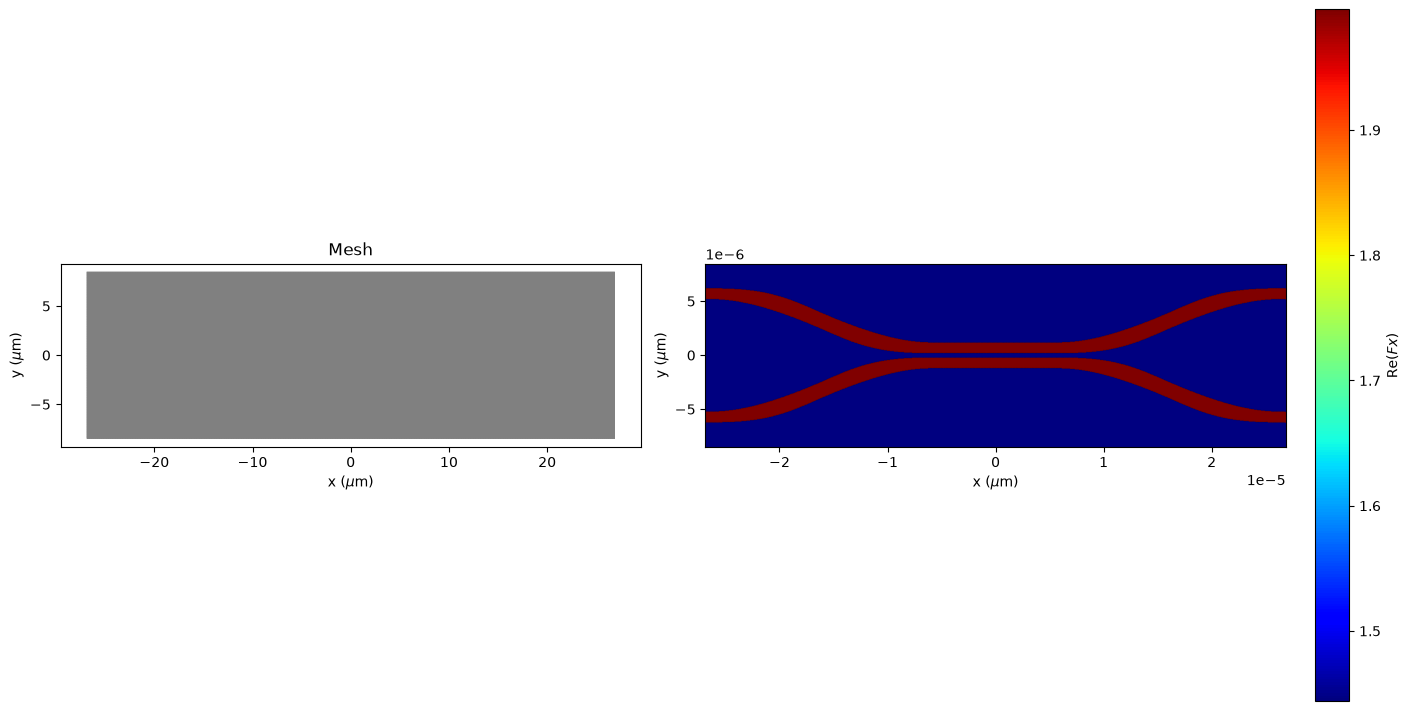

In [319]:
# Simulation preview

index = solver.getresult("index-monitor", "index preview")
index_x, index_y, index_z = [np.squeeze(index[f"index_{a}"]) for a in ["x", "y", "z"]]
x, y = np.squeeze(index["x"]), np.squeeze(index["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

# Grid
X, Y = np.meshgrid(x, y, indexing='ij')
ax1.plot(X * 1e6, Y * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.plot(X.T * 1e6, Y.T * 1e6, color='gray', linestyle='-', linewidth=0.5)
ax1.set_title('Mesh')
ax1.set_xlabel(r'x ($\mu$m)')
ax1.set_ylabel(r'y ($\mu$m)')
ax1.set_aspect('equal')

# Refractive index
px.plot_field(
    Fx=index_x,
    x=x, y=y,
    ax=ax2,
    scale="lin",
)

solver.setnamed("index-monitor", "enabled", False)

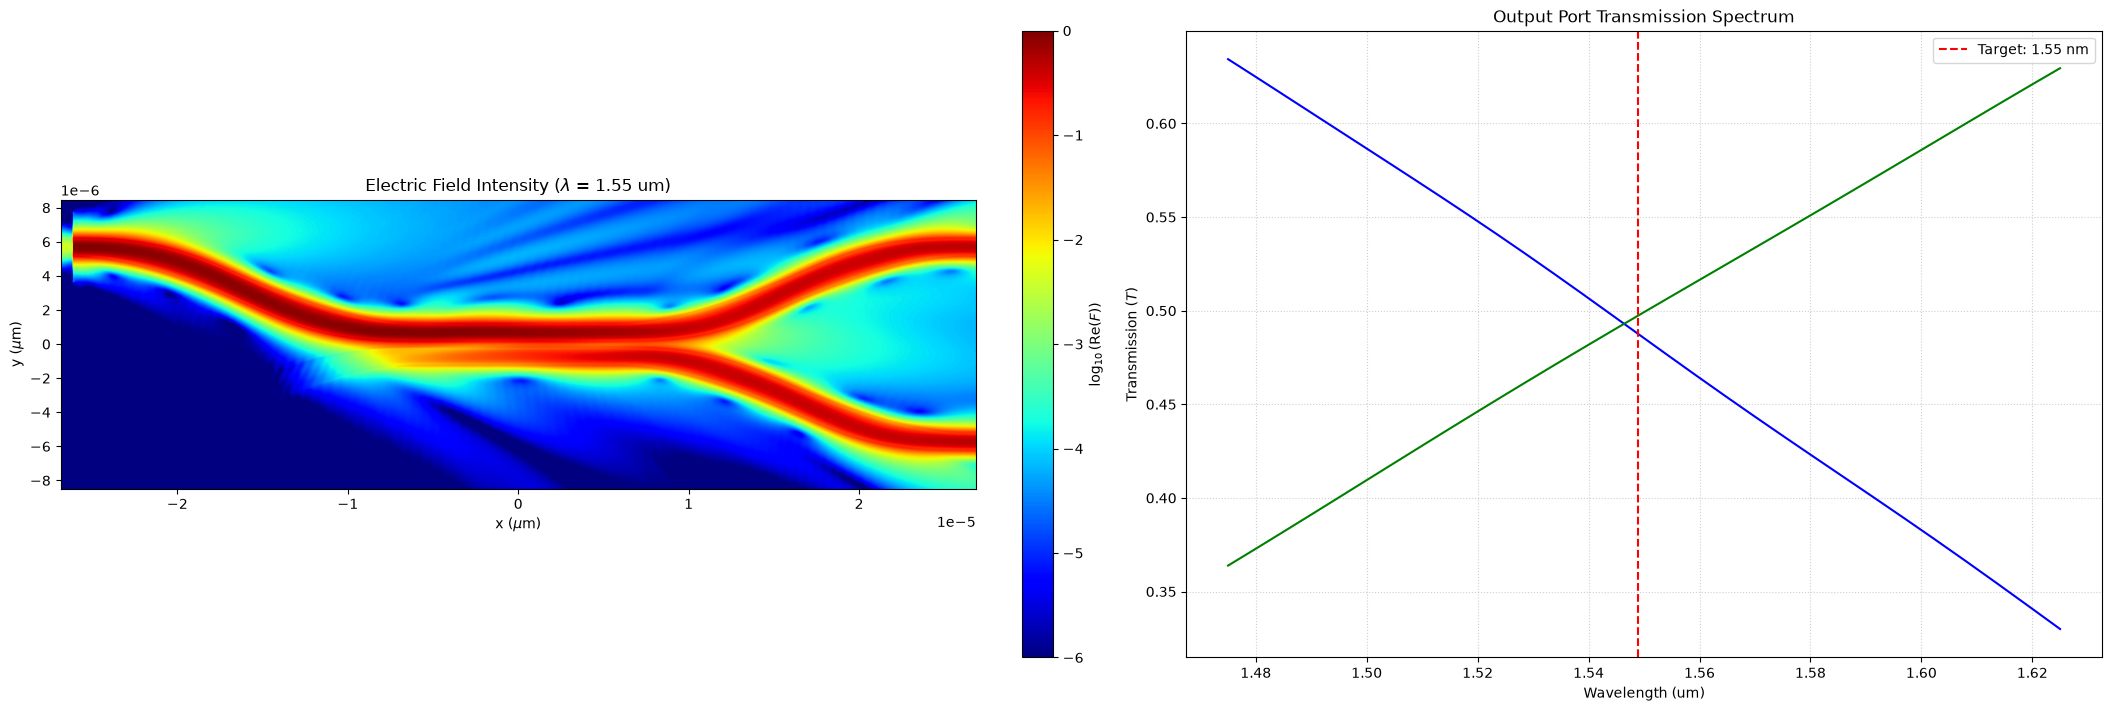

In [320]:
# Initial simulation

solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-6, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T3 = solver.getresult("FDTD::ports::port3-out", "T")
wavelengths = np.squeeze(T3["lambda"])
T3 = np.squeeze(T3["T"])

T4 = solver.getresult("FDTD::ports::port4-out", "T")
T4 = np.squeeze(T4["T"])


ax2.plot(wavelengths*1e6, T3, color='b')
ax2.plot(wavelengths*1e6, T4, color='g')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

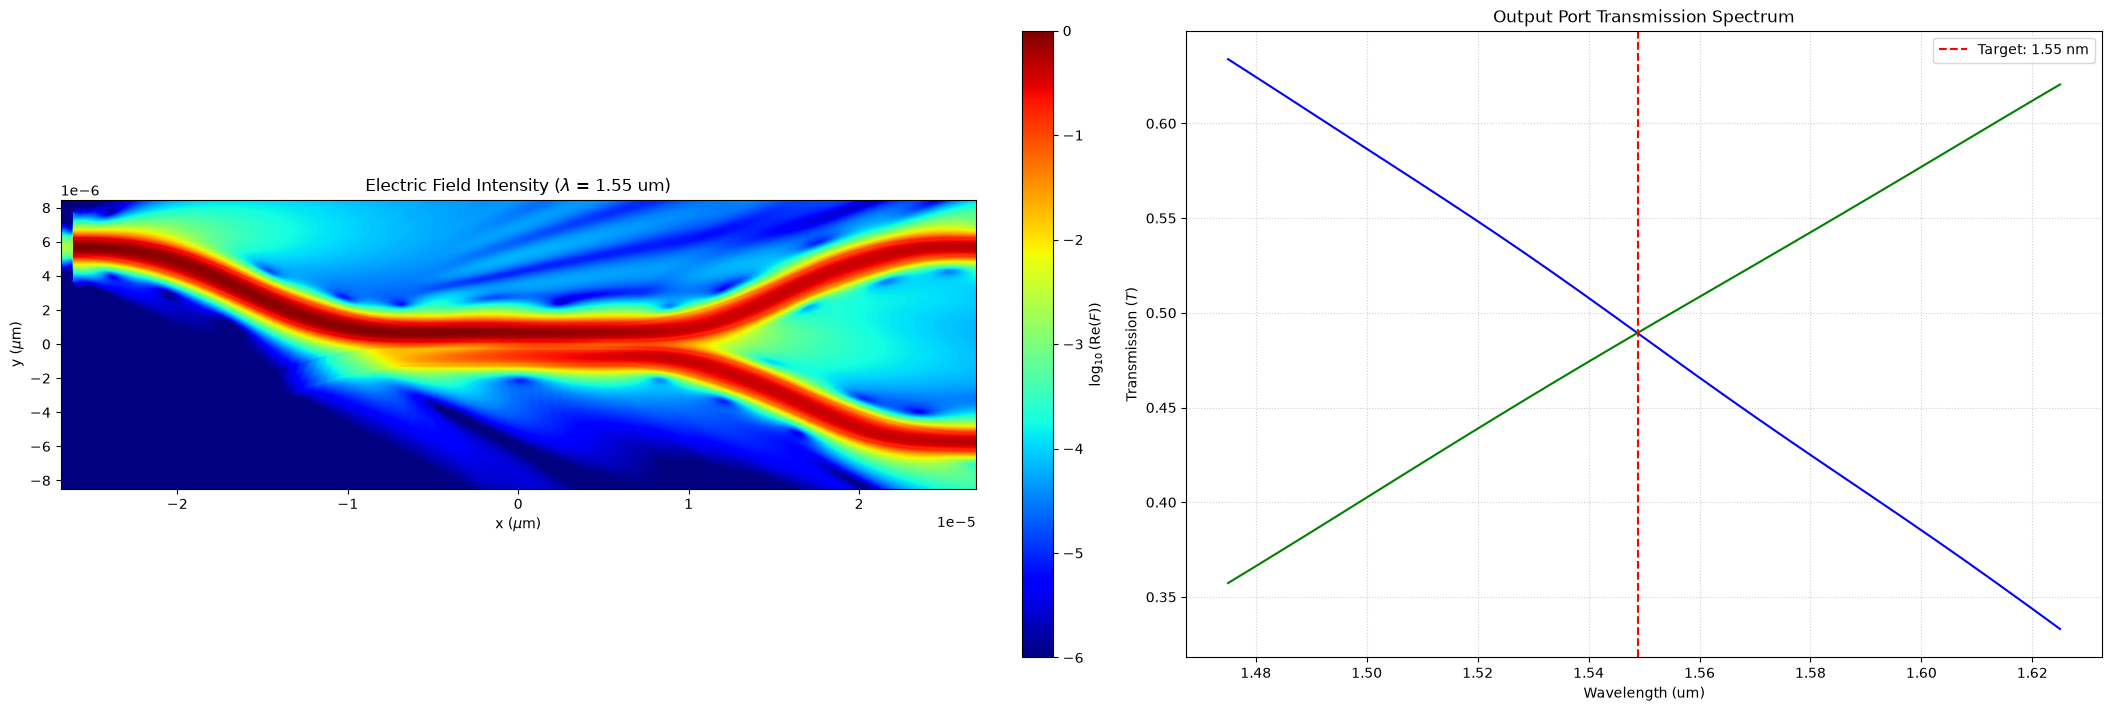

In [322]:
# Second simulation (denser mesh)

solver.switchtolayout()
solver.setnamed("FDTD", "mesh accuracy", 3)
solver.setnamed("index-monitor", "enabled", False)

solver.run()

# Get E fields components from field-monitor
E = solver.getresult("field-monitor", "E")

# Get index of wavelength nearest center
lambdas = np.squeeze(E["lambda"])
lambda_idx = np.argmin(np.abs(lambdas - wavelength_center))
plot_wavelength = lambdas[lambda_idx]

Ex, Ey, Ez = [np.squeeze(E["E"][..., lambda_idx,i ]) for i in range(3)]
x, y = np.squeeze(E["x"]), np.squeeze(E["y"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(21, 7), constrained_layout=True)

# Efield
px.plot_field(
    Ex, Ey, Ez, 
    x=x, y=y,
    vmin=-6, vmax=0,
    ax=ax1
)
ax1.set_title(rf'Electric Field Intensity ($\lambda$ = {plot_wavelength*1e6:.2f} um)')

# Transmission
T3 = solver.getresult("FDTD::ports::port3-out", "T")
wavelengths = np.squeeze(T3["lambda"])
T3 = np.squeeze(T3["T"])

T4 = solver.getresult("FDTD::ports::port4-out", "T")
T4 = np.squeeze(T4["T"])


ax2.plot(wavelengths*1e6, T3, color='b')
ax2.plot(wavelengths*1e6, T4, color='g')
ax2.axvline(plot_wavelength*1e6, color='r', linestyle='--', label=f'Target: {plot_wavelength*1e6:.2f} nm')
ax2.set_xlabel('Wavelength (um)')
ax2.set_ylabel('Transmission ($T$)')
ax2.set_title('Output Port Transmission Spectrum')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.show()

In [323]:
# S-parameters

sweep_name = solver.addsweep(3)
solver.setsweep(sweep_name, "excite all ports", 0)
solver.setsweep(sweep_name, "auto symmetry", 1)
solver.runsweep("s-parameter sweep", "GPU");

# Export S-parameters
solver.exportsweep("s-parameter sweep", f"results/{experiment_name}.dat", "lumerical")


LumApiError: 'in exportsweep - error writing to results/si3n4_w1000nm_h360nm_directCoupler_g400nm_l12um.dat'